In [7]:
# === CELL 1 (NB3) — Reload/Resume ===
from google.colab import drive
drive.mount('/content/drive')

import sys, os
DRIVE_ROOT = "/content/drive/MyDrive/FPX_Project"
sys.path.insert(0, os.path.join(DRIVE_ROOT, "utils"))
import checkpoint_utils as cu

config = cu.load_json("config", "project_config")
print("=== CELL 1 (NB3) === Resumed FPX project.")
print(f"Current phase: {config.get('current_phase')}")
cu.project_status()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== CELL 1 (NB3) === Resumed FPX project.
Current phase: P2_setup
=== FPX Project Drive Status ===
config: 1 file(s)
   - project_config.json
data: 2 file(s)
   - client_partition.pkl
   - data_split.pkl
checkpoints/fl_sim: 0 file(s)
checkpoints/signals: 0 file(s)
checkpoints/interface: 0 file(s)
checkpoints/eval: 0 file(s)
outputs: 0 file(s)
logs: 1 file(s)
   - project_log.txt


In [8]:
# === CELL 2 (NB3) — Dependencies ===
import numpy as np
import torch, torch.nn as nn, copy
import matplotlib.pyplot as plt

print("=== CELL 2 (NB3) === torch:", torch.__version__)

=== CELL 2 (NB3) === torch: 2.11.0+cu128


In [9]:
# === CELL 3 (NB3) — Signal computation utilities ===
signal_utils_code = '''
import torch
import numpy as np

def flat_params(state_dict):
    return torch.cat([v.float().view(-1) for v in state_dict.values()])

def compute_divergence_signals(client_states, global_state_before):
    """Per-client cosine similarity of their update vs the mean update this round,
    plus a z-score of how anomalous each client is relative to its peers THIS round."""
    global_flat = flat_params(global_state_before)
    deltas = [flat_params(s) - global_flat for s in client_states]
    mean_delta = torch.stack(deltas).mean(dim=0)
    sims = [torch.nn.functional.cosine_similarity(mean_delta.unsqueeze(0), d.unsqueeze(0)).item() for d in deltas]
    norms = [d.norm().item() for d in deltas]
    sims_arr = np.array(sims)
    mu, sigma = sims_arr.mean(), sims_arr.std() + 1e-8
    z_scores = ((sims_arr - mu) / sigma).tolist()
    return {"cos_sim": sims, "update_norm": norms, "z_score": z_scores}

def update_exclusion_state(z_scores, consecutive_low, round_num, warmup_rounds=5,
                            persistence_rounds=2, z_threshold=-1.0):
    """Stateful exclusion flagging: requires N consecutive anomalous rounds AFTER
    a warmup period, to avoid flagging normal early-training volatility as a fault."""
    excluded = [False] * len(z_scores)
    if round_num > warmup_rounds:
        for i, z in enumerate(z_scores):
            if z < z_threshold:
                consecutive_low[i] += 1
            else:
                consecutive_low[i] = 0
            if consecutive_low[i] >= persistence_rounds:
                excluded[i] = True
    else:
        for i in range(len(z_scores)):
            consecutive_low[i] = 0
    return excluded, consecutive_low

def compute_contribution_weights(base_weights, excluded, down_weight_factor=0.05):
    """Apply down-weighting to excluded clients' aggregation weight."""
    adj = [w * down_weight_factor if e else w for w, e in zip(base_weights, excluded)]
    total = sum(adj)
    effective_share = [a / total for a in adj]
    return adj, effective_share
'''

util_path = os.path.join(DRIVE_ROOT, "utils", "signal_utils.py")
with open(util_path, "w") as f:
    f.write(signal_utils_code)

sys.path.insert(0, os.path.join(DRIVE_ROOT, "utils"))
import signal_utils as su

print("=== CELL 3 (NB3) === signal_utils.py written to Drive and imported.")

=== CELL 3 (NB3) === signal_utils.py written to Drive and imported.


In [10]:
# === DEBUG — check what's actually on Drive ===
import os
data_dir = os.path.join(DRIVE_ROOT, "data")
print("Contents of data/ folder:")
if os.path.exists(data_dir):
    for f in os.listdir(data_dir):
        print(" -", f)
else:
    print("data/ folder does not exist at all")

cu.project_status()

Contents of data/ folder:
 - client_partition.pkl
 - data_split.pkl
=== FPX Project Drive Status ===
config: 1 file(s)
   - project_config.json
data: 2 file(s)
   - client_partition.pkl
   - data_split.pkl
checkpoints/fl_sim: 21 file(s)
   - latest_round_state.pkl
   - round_001.pkl
   - round_002.pkl
   - round_003.pkl
   - round_004.pkl
   - round_005.pkl
   - round_006.pkl
   - round_007.pkl
   - round_008.pkl
   - round_009.pkl
checkpoints/signals: 0 file(s)
checkpoints/interface: 0 file(s)
checkpoints/eval: 0 file(s)
outputs: 0 file(s)
logs: 1 file(s)
   - project_log.txt


In [11]:
# === CELL 4 (NB3) — Load existing data split + partition ===
split = cu.load_pickle("data", "data_split")
client_indices = cu.load_pickle("data", "client_partition")

if split is None or client_indices is None:
    raise RuntimeError("Missing data split or partition — run Notebook 2 first.")

X_train, X_test, y_train, y_test = split["X_train"], split["X_test"], split["y_train"], split["y_test"]
print(f"=== CELL 4 (NB3) === Loaded {len(client_indices)} clients from Drive.")
for i, idx in enumerate(client_indices):
    print(f"  Client {i}: n={len(idx)}")

=== CELL 4 (NB3) === Loaded 8 clients from Drive.
  Client 0: n=16
  Client 1: n=62
  Client 2: n=47
  Client 3: n=93
  Client 4: n=48
  Client 5: n=60
  Client 6: n=66
  Client 7: n=63


In [12]:
# === CELL 5 (NB3) — Model + fault injection setup ===
class SmallMLP(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 2))
    def forward(self, x):
        return self.net(x)

def local_train(global_state, X_c, y_c, in_dim, epochs=5, lr=0.05):
    model = SmallMLP(in_dim)
    model.load_state_dict(global_state)
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    Xt = torch.tensor(X_c, dtype=torch.float32)
    yt = torch.tensor(y_c, dtype=torch.long)
    model.train()
    for _ in range(epochs):
        opt.zero_grad()
        out = model(Xt)
        loss = loss_fn(out, yt)
        loss.backward()
        opt.step()
    return model.state_dict(), loss.item(), len(y_c)

# Ground-truth fault: Client 0's labels get shuffled from round 8 onward,
# simulating a hospital whose data pipeline silently corrupted labels.
FAULT_CONFIG = {"fault_client": 0, "fault_round": 8, "fault_type": "label_shuffle"}
WARMUP_ROUNDS = 5
PERSISTENCE_ROUNDS = 2
Z_THRESHOLD = -1.0
NUM_ROUNDS_ROBUST = 15

cu.save_json(FAULT_CONFIG, "config", "fault_config")
print("=== CELL 5 (NB3) === Model + fault config ready:", FAULT_CONFIG)

[2026-09-02 10:16:03] Saved JSON checkpoint: config/fault_config.json
=== CELL 5 (NB3) === Model + fault config ready: {'fault_client': 0, 'fault_round': 8, 'fault_type': 'label_shuffle'}


In [13]:
# === CELL 6 (NB3) — Robust FL simulation with signal-driven exclusion ===
in_dim = X_train.shape[1]
rng = np.random.default_rng(123)

resume = cu.load_pickle("checkpoints/fl_sim_robust", "latest_round_state")

if resume is not None:
    global_model = SmallMLP(in_dim)
    global_model.load_state_dict(resume["global_state"])
    signal_history = resume["signal_history"]
    consecutive_low = resume["consecutive_low"]
    start_round = resume["round"] + 1
    print(f"=== CELL 6 (NB3) === Resuming robust simulation from round {start_round}")
else:
    global_model = SmallMLP(in_dim)
    signal_history = []
    consecutive_low = [0] * len(client_indices)
    start_round = 1
    print("=== CELL 6 (NB3) === Starting fresh robust simulation")

for rnd in range(start_round, NUM_ROUNDS_ROBUST + 1):
    global_state_before = copy.deepcopy(global_model.state_dict())

    client_states, client_weights = [], []
    for i, idx in enumerate(client_indices):
        Xc, yc = X_train[idx], y_train[idx].copy()
        if i == FAULT_CONFIG["fault_client"] and rnd >= FAULT_CONFIG["fault_round"]:
            yc = rng.permutation(yc)
        state, loss, n = local_train(global_state_before, Xc, yc, in_dim)
        client_states.append(state)
        client_weights.append(n)

    divergence = su.compute_divergence_signals(client_states, global_state_before)
    excluded, consecutive_low = su.update_exclusion_state(
        divergence["z_score"], consecutive_low, rnd,
        warmup_rounds=WARMUP_ROUNDS, persistence_rounds=PERSISTENCE_ROUNDS, z_threshold=Z_THRESHOLD
    )
    adj_weights, effective_share = su.compute_contribution_weights(client_weights, excluded)

    total = sum(adj_weights)
    avg_state = copy.deepcopy(client_states[0])
    for key in avg_state:
        avg_state[key] = sum(client_states[i][key].float() * (adj_weights[i] / total) for i in range(len(client_states)))
    global_model.load_state_dict(avg_state)

    global_model.eval()
    with torch.no_grad():
        preds = global_model(torch.tensor(X_test, dtype=torch.float32)).argmax(dim=1).numpy()
    acc = (preds == y_test).mean()

    round_record = {
        "round": rnd, "test_accuracy": float(acc),
        "cos_sim": divergence["cos_sim"], "update_norm": divergence["update_norm"],
        "z_score": divergence["z_score"], "excluded": excluded, "effective_share": effective_share,
        "is_fault_round": rnd >= FAULT_CONFIG["fault_round"]
    }
    signal_history.append(round_record)

    cu.save_pickle(
        {"global_state": avg_state, "signal_history": signal_history, "consecutive_low": consecutive_low, "round": rnd},
        "checkpoints/fl_sim_robust", "latest_round_state"
    )

    flag_str = f"EXCLUDED:{[i for i,e in enumerate(excluded) if e]}" if any(excluded) else ""
    print(f"=== CELL 6 (NB3) === Round {rnd}/{NUM_ROUNDS_ROBUST} | acc={acc:.4f} | "
          f"client0_z={divergence['z_score'][0]:+.2f} {flag_str}")

print("=== CELL 6 (NB3) === Robust simulation complete.")

=== CELL 6 (NB3) === Starting fresh robust simulation
[2026-09-02 10:16:25] Saved pickle checkpoint: checkpoints/fl_sim_robust/latest_round_state.pkl
=== CELL 6 (NB3) === Round 1/15 | acc=0.6316 | client0_z=-0.69 
[2026-09-02 10:16:25] Saved pickle checkpoint: checkpoints/fl_sim_robust/latest_round_state.pkl
=== CELL 6 (NB3) === Round 2/15 | acc=0.6667 | client0_z=-0.79 
[2026-09-02 10:16:25] Saved pickle checkpoint: checkpoints/fl_sim_robust/latest_round_state.pkl
=== CELL 6 (NB3) === Round 3/15 | acc=0.7368 | client0_z=-0.70 
[2026-09-02 10:16:25] Saved pickle checkpoint: checkpoints/fl_sim_robust/latest_round_state.pkl
=== CELL 6 (NB3) === Round 4/15 | acc=0.8333 | client0_z=-0.35 
[2026-09-02 10:16:25] Saved pickle checkpoint: checkpoints/fl_sim_robust/latest_round_state.pkl
=== CELL 6 (NB3) === Round 5/15 | acc=0.8509 | client0_z=-0.18 
[2026-09-02 10:16:25] Saved pickle checkpoint: checkpoints/fl_sim_robust/latest_round_state.pkl
=== CELL 6 (NB3) === Round 6/15 | acc=0.8860 | cli

[2026-09-02 10:17:30] Saved pickle checkpoint: checkpoints/signals/signal_timeline.pkl
[2026-09-02 10:17:30] Saved JSON checkpoint: checkpoints/signals/fault_config_used.json


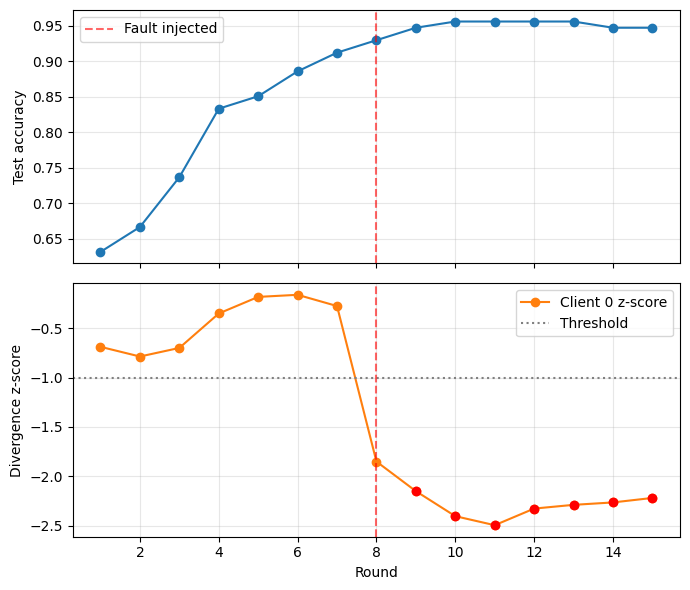

[2026-09-02 10:17:32] Saved JSON checkpoint: config/project_config.json
=== CELL 7 (NB3) === Signal timeline saved (15 rounds).
Red dots = rounds where Client 0 was flagged and down-weighted.


In [14]:
# === CELL 7 (NB3) — Save signal timeline + plots ===
os.makedirs(os.path.join(DRIVE_ROOT, "outputs"), exist_ok=True)

cu.save_pickle(signal_history, "checkpoints/signals", "signal_timeline")
cu.save_json(FAULT_CONFIG, "checkpoints/signals", "fault_config_used")

rounds = [h["round"] for h in signal_history]
accs = [h["test_accuracy"] for h in signal_history]
z0 = [h["z_score"][0] for h in signal_history]
excl0 = [h["excluded"][0] for h in signal_history]

fig, axes = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
axes[0].plot(rounds, accs, marker="o", color="tab:blue")
axes[0].axvline(FAULT_CONFIG["fault_round"], color="red", linestyle="--", alpha=0.6, label="Fault injected")
axes[0].set_ylabel("Test accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(rounds, z0, marker="o", color="tab:orange", label="Client 0 z-score")
axes[1].axhline(Z_THRESHOLD, color="gray", linestyle=":", label="Threshold")
axes[1].axvline(FAULT_CONFIG["fault_round"], color="red", linestyle="--", alpha=0.6)
for r, e in zip(rounds, excl0):
    if e:
        axes[1].scatter(r, z0[r-1], color="red", zorder=5)
axes[1].set_ylabel("Divergence z-score")
axes[1].set_xlabel("Round")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(DRIVE_ROOT, "outputs", "signal_timeline.png"), dpi=120, bbox_inches="tight")
plt.show()

config["current_phase"] = "P3_complete"
cu.save_json(config, "config", "project_config")

print(f"=== CELL 7 (NB3) === Signal timeline saved ({len(signal_history)} rounds).")
print("Red dots = rounds where Client 0 was flagged and down-weighted.")